# 01 — Data and quality checks

This notebook processes the data up to a clean **point-in-time** panel: 
- it builds the daily panel of the 500 largest US stocks (2011-2024)
- checks the universe and the dating of the fundamentals, and saves it to `data/panel_clean.parquet`, the file read by `02_strategy.ipynb`.
- §1 and §2 was done before the beginning of the hackaton 


**The data is not in this repo.** It comes from S&P Global Compustat through the MaQI platform,
and the licence forbids it from leaving the platform. This notebook therefore runs on the MaQI
JupyterHub. On the first run it rebuilds the panel from S3 into `data/` (a folder ignored by
git). No cell displays an individual row: we publish aggregated results, never rows.

## 1. Parameters and imports

Every choice made in this notebook is set here, each with its justification.

In [12]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# --- Data location ------------------------------------------------------------------------
DATA_DIR = Path("data")                        # ignored by git: Compustat rows stay on the platform
RAW_PATH = DATA_DIR / "daily.parquet"          # raw panel, built from S3 on the first run (~20 s)
CLEAN_PATH = DATA_DIR / "panel_clean.parquet"  # output of this notebook, input of 02_strategy.ipynb

# --- Universe -----------------------------------------------------------------------------
SNAPSHOT = "20260711"   # frozen S&P Global snapshot: same data for every team, reproducible results
FIRST_YEAR = 2011       # first membership year; 2010 only serves as history (momentum looks back 12 months)
LAST_YEAR = 2024        # last complete year of the snapshot
UNIVERSE_SIZE = 500     # the 500 largest US market caps, re-selected at each year end (assignment)

# --- Compustat rules (reading the S3 mirror) ----------------------------------------------
STANDARD = (("CONSOL", "C"), ("POPSRC", "D"))  # consolidated, domestic statements: the "standard" version of a quarter
STANDARD_FORMATS = ("PRE_AMENDS", "STD")       # vendor ordering: the original version before the amended one
RAW_FIELDS = ("CSHOQ", "CEQQ", "SEQQ", "ATQ", "DLTTQ", "DLCQ", "NIQ",
              "OIADPQ", "REVTQ", "TXTQ", "ACTQ", "LCTQ")  # the 12 quarterly fields delivered

pd.set_option("display.width", 160)

## 2. Loading and merging

The panel is assembled from five tables of the Compustat mirror (snapshot `20260711`):

| table | content |
|---|---|
| `prices-daily/f_sec_dprc` | raw close, split factor `AJEXDI`, volume, share count |
| `total-returns/f_sec_dtrt` | total-return factor `TRFD` (dividends, spin-offs) |
| `fundamentals-quarterly/f_co_ifndqV2` | the 12 quarterly fields |
| `filing-dates/f_co_filedate` | the filing date of each quarter |
| `reference/*` | issue, exchange, GICS sector |

The construction choices, taken as-is from the project package:

- **Point-in-time universe.** For each year Y, we take the 500 largest market caps
  (`PRCCD × CSHOC`) on the last trading day of Y-1. Only US common stocks (NYSE, NYSE American,
  Nasdaq) in their primary issue are kept.
- **History around the membership year.** Each membership year carries the year before (for
  lookbacks) and the year after, flagged `in_universe=False`.
- **Prices.** `adj_close = close / adj_factor`: divide, never multiply. `ret_1d` is set to NaN
  across a change of issue, a gap of more than 7 days, or a move of more than 100%.
- **Fundamentals.** We keep the first filed version of each quarter. It is in force from its
  **filing date** (`available_from`), never from the fiscal quarter end (`datadate`). A quarter
  with no filing date is dropped.

The function below is the project's S3 rebuild. It is only called if `data/daily.parquet` does
not exist yet. `maqi_data` is the platform library that provides temporary S3 credentials.

In [13]:
def build_panel(path: Path, *, snapshot: str = SNAPSHOT, first_year: int = FIRST_YEAR,
                last_year: int = LAST_YEAR, size: int = UNIVERSE_SIZE) -> Path:
    """Rebuild the daily panel from S3 and write it to `path` (~20 seconds)."""
    import warnings

    import maqi_data as maqi
    import polars as pl

    # Both as-of joins sort explicitly first; polars cannot verify that through a `by` group.
    warnings.filterwarnings("ignore", message="Sortedness of columns cannot be checked")

    options = maqi.get_credentials().as_storage_options()
    mirror = f"s3://maqi-spglobal-clean/spglobal/snapshot={snapshot}"

    def scan(folder: str, table: str) -> pl.LazyFrame:
        return pl.scan_parquet(f"{mirror}/{folder}/{table}/part-*.parquet",
                               storage_options=options, hive_partitioning=False)

    # ── the universe: the largest `size` at each prior year end ──
    px = scan("prices-daily", "f_sec_dprc").with_columns(date=pl.col("DATADATE").cast(pl.Date))
    ends = (px.filter((pl.col("date").dt.month() == 12) & (pl.col("date").dt.day() >= 20)
                      & (pl.col("CURCDD") == "USD")
                      & pl.col("date").dt.year().is_between(first_year - 1, last_year - 1))
              .group_by("date").len().filter(pl.col("len") > 2000)
              .group_by(pl.col("date").dt.year().alias("prior")).agg(pl.col("date").max())
              .with_columns(year=pl.col("prior") + 1).select("year", "date").collect())
    common = (scan("reference", "f_securityv2")
              .filter((pl.col("EXCNTRY") == "USA") & (pl.col("TPCI") == "0")
                      & pl.col("EXCHG").is_in([11, 12, 14]))
              .select("GVKEY", "IID"))
    primary = (scan("reference", "f_sec_history").filter(pl.col("ITEM") == "PRIHISTUSA")
               .select("GVKEY", primary="ITEMVALUE", eff=pl.col("EFFDATE").cast(pl.Date),
                       thru=pl.col("THRUDATE").cast(pl.Date)).collect())
    snap = (px.filter(pl.col("date").is_in(ends["date"].to_list()) & (pl.col("CURCDD") == "USD")
                      & (pl.col("PRCCD") > 0) & (pl.col("CSHOC") > 0))
              .join(common, on=["GVKEY", "IID"], how="semi")
              .select("GVKEY", "IID", "date", mcap=pl.col("PRCCD") * pl.col("CSHOC")).collect()
              .join(primary, on="GVKEY")
              .filter((pl.col("IID") == pl.col("primary")) & (pl.col("date") >= pl.col("eff"))
                      & (pl.col("thru").is_null() | (pl.col("date") <= pl.col("thru"))))
              .unique(["GVKEY", "date"]))
    members = (snap.join(ends, on="date")
                   .with_columns(rank=pl.col("mcap").rank("ordinal", descending=True).over("year"))
                   .filter(pl.col("rank") <= size)
                   .select("year", gvkey="GVKEY", iid="IID"))
    gv = members["gvkey"].unique().to_list()

    # ── prices: the membership year's issue, carried into the gaps ──
    years = pl.DataFrame({"year": list(range(first_year - 1, last_year + 1))})
    issue = (pl.DataFrame({"gvkey": gv}).join(years, how="cross")
               .join(members.select("gvkey", "year", "iid"), on=["gvkey", "year"], how="left")
               .sort("gvkey", "year")
               .with_columns(pl.col("iid").forward_fill().backward_fill().over("gvkey")))
    prices = (scan("prices-daily", "f_sec_dprc")
              .filter(pl.col("GVKEY").is_in(gv) & (pl.col("CURCDD") == "USD")
                      & pl.col("DATADATE").cast(pl.Date).is_between(pl.date(first_year - 1, 1, 1),
                                                                     pl.date(last_year, 12, 31)))
              .select(gvkey="GVKEY", iid="IID", date=pl.col("DATADATE").cast(pl.Date),
                      close="PRCCD", adj_factor="AJEXDI", volume="CSHTRD", shares="CSHOC")
              .with_columns(year=pl.col("date").dt.year())
              .join(issue.lazy(), on=["gvkey", "year", "iid"], how="semi")
              .filter((pl.col("close") > 0) & (pl.col("adj_factor") > 0))
              .collect())
    daily = pl.col("adj_close").pct_change().over("gvkey")
    frame = (prices.sort("gvkey", "date")
               .with_columns(adj_close=pl.col("close") / pl.col("adj_factor"),     # DIVIDE
                             dollar_volume=pl.col("close") * pl.col("volume"))
               .with_columns(ret_1d=pl.when((pl.col("date").diff().over("gvkey").dt.total_days() <= 7)
                                            & (pl.col("iid") == pl.col("iid").shift(1).over("gvkey"))
                                            & (daily.abs() <= 1.0))
                                      .then(daily))
               .join(members.select("gvkey", "year", in_universe=pl.lit(True)),
                     on=["gvkey", "year"], how="left")
               .with_columns(pl.col("in_universe").fill_null(False)))
    near = pl.concat([members.select("gvkey", year=pl.col("year") + d) for d in (-1, 0, 1)]).unique()
    frame = frame.join(near, on=["gvkey", "year"], how="semi")

    # ── total-return factor: cumulative, missing means no distribution yet ──
    trfd = (scan("total-returns", "f_sec_dtrt").filter(pl.col("GVKEY").is_in(gv))
            .select(gvkey="GVKEY", iid="IID", start=pl.col("DATADATE").cast(pl.Date),
                    thru=pl.col("THRUDATE").cast(pl.Date), trfd="TRFD").sort("start").collect())
    frame = (frame.sort("date").join_asof(trfd, left_on="date", right_on="start",
                                          by=["gvkey", "iid"], strategy="backward")
                  .with_columns(pl.col("trfd").fill_null(1.0))
                  .drop("start", "thru"))

    # ── fundamentals: the first filed version, in force from its filing date ──
    standard = pl.all_horizontal([pl.col(c) == v for c, v in STANDARD])
    filed = (scan("filing-dates", "f_co_filedate")
             .select("GVKEY", "CONSOL", "POPSRC", datadate=pl.col("DATADATE").cast(pl.Date),
                     filedate=pl.col("FILEDATE").cast(pl.Date))
             .filter(pl.col("filedate").is_between(pl.col("datadate"),
                                                   pl.col("datadate").dt.offset_by("1y")))
             .group_by("GVKEY", "CONSOL", "POPSRC", "datadate")
             .agg(available_from=pl.col("filedate").min()))
    keys = ["GVKEY", "datadate", "INDFMT", "DATAFMT", "CONSOL", "POPSRC"]
    filled = pl.sum_horizontal([pl.col(f).is_not_null() for f in RAW_FIELDS])
    statements = (scan("fundamentals-quarterly", "f_co_ifndqV2")
                  .filter(pl.col("GVKEY").is_in(gv) & standard
                          & pl.col("DATAFMT").is_in(STANDARD_FORMATS))
                  .select(*keys[:1], *keys[2:], datadate=pl.col("DATADATE").cast(pl.Date),
                          **{f: pl.col(f).cast(pl.Float64) for f in RAW_FIELDS})
                  .collect()
                  .with_row_index("_order").with_columns(_filled=filled)
                  .sort([*keys, "_filled"], descending=[False] * len(keys) + [True],
                        maintain_order=True)
                  .unique(keys, keep="first", maintain_order=True)
                  .sort("_order").drop("_filled", "_order"))
    industrial = (statements.sort(["GVKEY", "datadate", pl.col("INDFMT") != "INDL"],
                                  maintain_order=True)
                            .unique(["GVKEY", "datadate"], keep="first", maintain_order=True)
                            .select("GVKEY", "datadate", "INDFMT"))
    version = pl.col("DATAFMT").replace_strict(
        {name: i for i, name in enumerate(STANDARD_FORMATS)}, default=len(STANDARD_FORMATS))
    fund = (statements.join(industrial, on=["GVKEY", "datadate", "INDFMT"], how="inner")
            .join(filed.collect(), on=["GVKEY", "CONSOL", "POPSRC", "datadate"], how="left")
            .sort(["GVKEY", "datadate", "INDFMT", version, "DATAFMT"], maintain_order=True)
            .unique(["GVKEY", "datadate", "INDFMT"], keep="first", maintain_order=True)
            .filter(pl.col("available_from").is_not_null())
            .select("datadate", "available_from", gvkey="GVKEY", *RAW_FIELDS)
            .sort("gvkey", "available_from", "datadate")
            .filter(pl.col("datadate") > pl.col("datadate").cum_max().shift(1).over("gvkey")
                    .fill_null(pl.date(1900, 1, 1)))
            .unique(["gvkey", "available_from"], keep="last", maintain_order=True)
            .sort("available_from"))
    frame = frame.sort("date").join_asof(fund, left_on="date", right_on="available_from",
                                         by="gvkey", strategy="backward")

    # ── names: I/B/E/S ticker, GICS sector ──
    gics = {10: "Energy", 15: "Materials", 20: "Industrials", 25: "Consumer Discretionary",
            30: "Consumer Staples", 35: "Health Care", 40: "Financials",
            45: "Information Technology", 50: "Communication Services",
            55: "Utilities", 60: "Real Estate"}
    ticker = (scan("reference", "f_securityv2").filter(pl.col("GVKEY").is_in(gv))
              .select(gvkey="GVKEY", iid="IID", ibtic="IBTIC").collect())
    last_issue = members.sort("year").group_by("gvkey").agg(pl.col("iid").last())
    names = (scan("reference", "f_company").filter(pl.col("GVKEY").is_in(gv))
             .select(gvkey="GVKEY", name="CONM",
                     gsector=pl.col("GSECTOR").cast(pl.Int64, strict=False)).collect()
             .join(last_issue.join(ticker, on=["gvkey", "iid"], how="left").select("gvkey", "ibtic"),
                   on="gvkey", how="left")
             .with_columns(ticker=pl.coalesce("ibtic", pl.lit("GV") + pl.col("gvkey")),
                           gics_sector=pl.col("gsector").replace_strict(gics, default=None))
             .select("gvkey", "ticker", "name", "gics_sector"))

    out = (frame.join(names, on="gvkey", how="left")
                .select("date", "gvkey", "iid", "ticker", "name", "gics_sector", "in_universe",
                        "close", "adj_factor", "adj_close", "volume", "dollar_volume", "shares",
                        "ret_1d", "trfd", "datadate", "available_from", *RAW_FIELDS)
                .sort("gvkey", "date")
                .with_columns(pl.col("date", "datadate", "available_from").cast(pl.Datetime("ms"))))
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_suffix(".partial")
    out.write_parquet(partial, compression="zstd")
    partial.replace(path)                 # an interrupted build leaves no half-written file
    return path

Build the panel if it does not exist yet, then read it. The table only reports aggregated
dimensions.

In [4]:
if not RAW_PATH.exists():
    build_panel(RAW_PATH)
frame = pd.read_parquet(RAW_PATH)

pd.Series({
    "rows": f"{len(frame):,}",
    "companies": frame["gvkey"].nunique(),
    "first date": f"{frame['date'].min():%Y-%m-%d}",
    "last date": f"{frame['date'].max():%Y-%m-%d}",
    "universe member rows": f"{int(frame['in_universe'].sum()):,}",
    "duplicates (gvkey, date)": int(frame.duplicated(["gvkey", "date"]).sum()),
}, name="raw panel").to_frame()

,raw panel
rows,"2,113,900"
companies,891
first date,2010-01-04
last date,2024-12-31
universe member rows,"1,746,126"
"duplicates (gvkey, date)",0


## 3. Universe: top 500 and survivorship bias

The universe is chosen **at each year end with the information available on that date**. A
company that later went bankrupt, was acquired or was delisted therefore stays in the panel for
the years it was a member. This is what avoids survivorship bias: taking the 500 largest caps of
2024 and going back in time would keep only the winners.

We check three things: 
- the number of members per day (about 500 expected),
- the yearly turnover of the universe
- the share of members that disappear from the tape before the end of the panel.

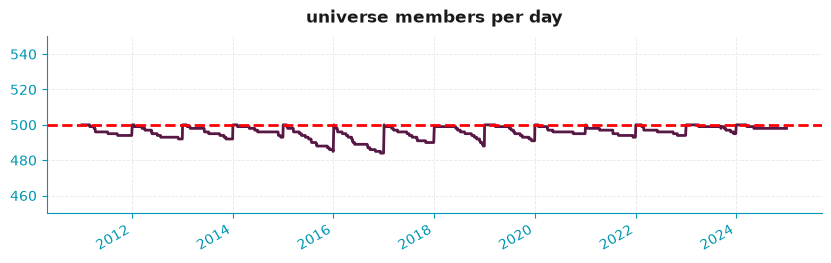

,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
members,500.0,500,500,500,500,500,500,499,500,500,500,500,500,500
entries,NaN,46,35,49,44,55,44,43,54,43,61,48,58,41
exits,NaN,46,35,49,44,55,44,44,53,43,61,48,58,41


In [31]:
members = frame.loc[frame["in_universe"]]
per_day = members.groupby("date").size()

# Plot the number of members in the S&P 500 index
g, ax = plt.subplots(figsize=(10, 2.6))
per_day.plot(ax=ax)
ax.axhline(UNIVERSE_SIZE, color="red", ls="--")
ax.set(title="universe members per day", ylim=(450,550), xlabel="")
plt.show()

# Compute the turn over
by_year = members.groupby(members["date"].dt.year)["gvkey"].agg(set) #give Pandas serie in outcome

turnover_rows, previous = {}, None

for year, names in by_year.items():
    
    turnover_rows[year] = {"members": len(names),
                           "entries": len(names - previous) if previous is not None else np.nan,
                           "exits": len(previous - names) if previous is not None else np.nan}
    previous = names

pd.DataFrame(turnover_rows)

A company "leaves the tape" when its last price in the panel is more than ten days before the end
of the panel. These companies are the evidence that the panel is not built on survivors.

In [35]:
last_seen = frame.groupby("gvkey")["date"].max()
ever_members = members["gvkey"].unique()
delisted = last_seen.loc[ever_members] < frame["date"].max() - pd.Timedelta(days=10) # 10 is arbitrary only for the safety margin 

survivorship = pd.Series({
    "companies ever in the universe": len(ever_members),
    "of which left the tape before the end of the panel": int(delisted.sum()),
    "share": f"{delisted.mean():.1%}",
}, name="survivorship bias").to_frame()

survivorship

,survivorship bias
companies ever in the universe,891
of which left the tape before the end of the panel,359
share,40.3%


## 4. Point-in-time: publication lag of fundamentals

A quarter is only known to the market on the day it is **filed**. The panel attaches each
quarter from its filing date `available_from`, not from the fiscal quarter end `datadate`. Using
`datadate` would give fundamental signals several weeks of future information: it is the most
common look-ahead on this kind of data.

Three anti-look-ahead checks, which must all be zero:

1. no row uses a quarter before its filing date (`date < available_from`);
2. no filing date precedes the quarter end (`available_from < datadate`);
3. the quarter in force never goes back in time for a given company.

In [33]:
fund = frame.loc[frame["datadate"].notna()]
quarters = fund.drop_duplicates(["gvkey", "datadate"])
publication_lag = (quarters["available_from"] - quarters["datadate"]).dt.days
in_force = fund.sort_values(["gvkey", "date"])
goes_back = in_force.groupby("gvkey")["datadate"].diff().dt.days < 0

pit_checks = pd.Series({
    "rows using a quarter before its filing": int((fund["date"] < fund["available_from"]).sum()),
    "filings before the quarter end": int((quarters["available_from"] < quarters["datadate"]).sum()),
    "quarter in force going back in time": int(goes_back.sum()),
    "distinct quarters": len(quarters),
    "median publication lag (days)": publication_lag.median(),
    "publication lag, 90th percentile (days)": publication_lag.quantile(0.9),
}, name="point-in-time").to_frame()

pit_checks

,point-in-time
rows using a quarter before its filing,0.0
filings before the quarter end,0.0
quarter in force going back in time,0.0
distinct quarters,34450.0
median publication lag (days),29.0
"publication lag, 90th percentile (days)",40.0


Distribution of the lag between the quarter end and its filing. Everything to the right of zero
is information that `datadate` would have handed over too early.

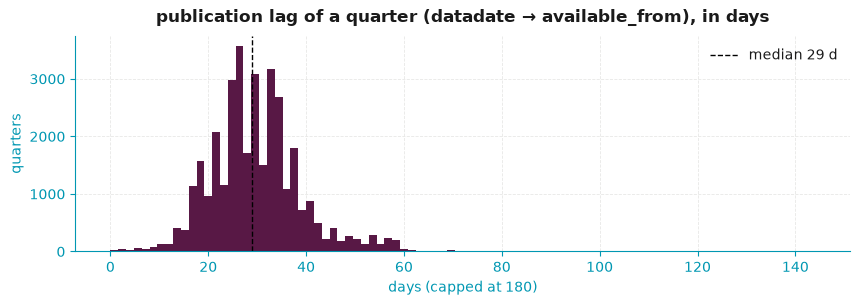

In [34]:
fig, ax = plt.subplots(figsize=(10, 2.8))
publication_lag.clip(upper=180).plot.hist(bins=90, ax=ax)
ax.axvline(publication_lag.median(), color="k", lw=1, ls="--",
           label=f"median {publication_lag.median():.0f} d")
ax.set(title="publication lag of a quarter (datadate → available_from), in days",
       xlabel="days (capped at 180)", ylabel="quarters")
ax.legend()
plt.show()

## 5. Summary of the checks and save

Each row repeats a check from the previous sections, with the expected value.

In [9]:
checks = pd.DataFrame([
    ("duplicates (gvkey, date)", frame.duplicated(["gvkey", "date"]).sum(), "0"),
    ("members per day, minimum", per_day.min(), f"≈ {UNIVERSE_SIZE}"),
    ("members per day, maximum", per_day.max(), f"≤ {UNIVERSE_SIZE}"),
    ("companies that left the tape (survivorship handled)", int(delisted.sum()), "> 0"),
    ("rows using a quarter before its filing", int((fund["date"] < fund["available_from"]).sum()), "0"),
    ("filings before the quarter end", int((quarters["available_from"] < quarters["datadate"]).sum()), "0"),
    ("quarter in force going back in time", int(goes_back.sum()), "0"),
], columns=["check", "value", "expected"]).set_index("check")
checks

,value,expected
check,,
"duplicates (gvkey, date)",0,0
"members per day, minimum",484,≈ 500
"members per day, maximum",500,≤ 500
companies that left the tape (survivorship handled),359,> 0
rows using a quarter before its filing,0,0
filings before the quarter end,0,0
quarter in force going back in time,0,0


We save the point-in-time panel. Exploration, data loopholes and feature design happen in
`02_strategy.ipynb`, so every raw field is kept; only the name columns are dropped, since nothing
downstream needs them. The file stays in `data/`, which is ignored by git.

In [10]:
CLEAN_COLUMNS = [c for c in frame.columns if c not in ("ticker", "name")]
DATA_DIR.mkdir(exist_ok=True)
frame[CLEAN_COLUMNS].to_parquet(CLEAN_PATH, index=False)
pd.Series({"file": str(CLEAN_PATH), "rows": f"{len(frame):,}", "columns": len(CLEAN_COLUMNS)},
          name="saved panel").to_frame()

,saved panel
file,data/panel_clean.parquet
rows,"2,113,900"
columns,27
